In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from mol_faith.target_extraction.benzene_substructure_extraction import BenzeneSubstructureExtractor
from mol_faith.target_extraction.hbond_donor_extraction import HBondDonorExtractor
from mol_faith.target_extraction.largest_conjugated_system_extraction import LargestConjugatedSystemExtractor

class GTAtomAnalyzer:
    def __init__(self, data_path: str, save_path: str):
        self.data = pd.read_csv(data_path)
        self.save_path = save_path
        self.target_names = ['conjugated_system', 'benzene', 'hbond_donor']

    def calculate_gt_label(self):
        extractors = {
            'benzene': BenzeneSubstructureExtractor().get_substructure_count,
            'conjugated_system': LargestConjugatedSystemExtractor().get_conjugated_system_size,
            'hbond_donor': HBondDonorExtractor().get_hbond_donor_count
        }

        for extractor_type, extractor_func in extractors.items():
            self.data[f'{extractor_type}_label'] = self.data['SMILES'].apply(lambda smi: extractor_func(smi))

    def calculate_gt_atoms(self):
        extractors = {
            'benzene': BenzeneSubstructureExtractor().get_atom_and_bond_indices,
            'conjugated_system': LargestConjugatedSystemExtractor().get_atom_and_bond_indices,
            'hbond_donor': HBondDonorExtractor().get_atom_and_bond_indices
        }

        for extractor_type, extractor_func in extractors.items():
            self.data[f'{extractor_type}_num_atoms'] = self.data['SMILES'].apply(
        lambda smi: (
            len(np.array(extractor_func(Chem.MolFromSmiles(smi))[0]).flatten())
            if Chem.MolFromSmiles(smi) else 0
        )
    )

    def calculate_num_atoms(self):
        self.data['num_atoms'] = self.data['SMILES'].apply(
            lambda smi: Chem.MolFromSmiles(smi).GetNumAtoms()
        )

    def calculate_gt_fraction(self):
        for target_name in self.target_names:
            # Calculate fraction: target_atoms / total_atoms
            self.data[f'{target_name}_fraction'] = self.data[f'{target_name}_num_atoms'] / self.data['num_atoms']

    def calculate_gt_label_avg(self):
        print('\n')
        for target_name in self.target_names:
            data_with_label = self.data[self.data[f'{target_name}_label'] > 0]
            print(f'Avg {target_name} gt label size: {data_with_label[f'{target_name}_label'].mean()}')

    def calculate_gt_atoms_avg(self):
        print('\n')
        for target_name in self.target_names:
            data_with_label = self.data[self.data[f'{target_name}_num_atoms'] > 0]
            print(f'Avg {target_name} gt atoms: {data_with_label[f'{target_name}_num_atoms'].mean().round(decimals=2)}')
            print(f'Std {target_name} gt atoms: {data_with_label[f'{target_name}_num_atoms'].std().round(decimals=2)}')

    def calculate_gt_fraction_avg(self):
        print('\n')
        for target_name in self.target_names:
            data_with_label = self.data[self.data[f'{target_name}_fraction'] > 0]
            print(f'Avg {target_name} gt fraction: {data_with_label[f'{target_name}_fraction'].mean().round(decimals=2)}')
            print(f'Std {target_name} gt fraction: {data_with_label[f'{target_name}_fraction'].std().round(decimals=2)}')

    def analyze_all_targets(self):
        self.calculate_gt_label()
        self.calculate_gt_atoms()
        self.calculate_num_atoms()
        self.calculate_gt_fraction()
        self.calculate_gt_label_avg()
        self.calculate_gt_atoms_avg()
        self.calculate_gt_fraction_avg()
        self.create_boxplot()

    def create_boxplot(self, save_path=None):
        all_fractions = []
        labels = []
        for target_name in self.target_names:
            data_with_label = self.data[self.data[f'{target_name}_num_atoms'] > 0].copy()
            fractions = data_with_label[f'{target_name}_fraction']
            all_fractions.extend(fractions)
            labels.extend([target_name] * len(fractions))

        plot_df = pd.DataFrame({
            'Target': labels,
            'GT_Fraction': all_fractions
        })

        def get_target_colors():
            return {
                'conjugated_system': '#9D8189',
                'benzene': '#F0CEA0',
                'hbond_donor': '#569A9F'
            }

        target_colors = get_target_colors()

        fig, ax = plt.subplots(figsize=(8, 6))

        sns.boxplot(
            data=plot_df,
            x='Target',
            y='GT_Fraction',
            ax=ax,
            palette=target_colors
        )

        ax.set_xlabel('Target')
        ax.set_ylabel('GT Atom Fraction')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, alpha=0.3)

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight', format='pdf')
            print(f"Box plot saved to: {save_path}")

        plt.show()

        return fig




Avg conjugated_system gt label size: 9.655562394214494
Avg benzene gt label size: 1.2017895299145298
Avg hbond_donor gt label size: 1.7070857142857143


Avg conjugated_system gt atoms: 9.66
Std conjugated_system gt atoms: 3.84
Avg benzene gt atoms: 7.21
Std benzene gt atoms: 2.54
Avg hbond_donor gt atoms: 1.71
Std hbond_donor gt atoms: 1.03


Avg conjugated_system gt fraction: 0.61
Std conjugated_system gt fraction: 0.24
Avg benzene gt fraction: 0.43
Std benzene gt fraction: 0.15
Avg hbond_donor gt fraction: 0.1
Std hbond_donor gt fraction: 0.06


/tmp/ipykernel_1156193/1296243495.py:106: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


AttributeError: module 'matplotlib.pyplot' has no attribute 'sd'

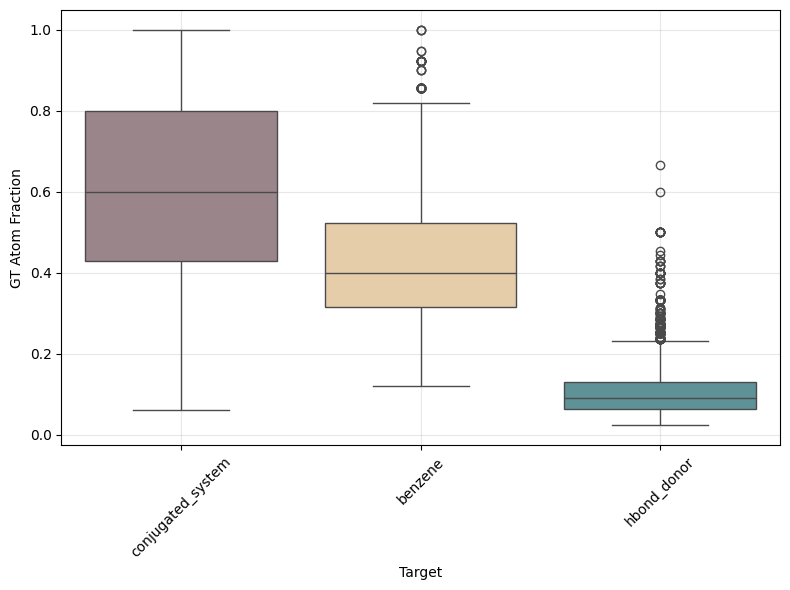

In [2]:
data_path = '../../../data/real_world/logp/cleaned_and_filtered/filtered_data.csv'
save_path = './gt_atom_fraction_analysis.pdf'

analyzer = GTAtomAnalyzer(data_path, save_path)
analyzer.analyze_all_targets()